# Notebook 3 — Estimación causal final (OE2–OE4 · bloques R3, R4, R5, R7 y dependencia espacial)

## Protocolo (fijado antes de estimar)

| Elemento | Decisión |
|---|---|
| Población | Avisos de alquiler de departamentos publicados en 13 distritos de Lima (marzo 2025), muestra auditada del notebook 2 con **geocodificación exacta (ROOFTOP)**, N = 2 220. Precio **de oferta**, no de contrato. |
| Tratamiento T | Número de baños (1–5). Intervención: *un baño adicional*, manteniendo fijos área, dormitorios, antigüedad y ubicación. |
| Resultado Y | log(precio mensual). θ se lee como cambio porcentual aproximado: 100·(e^θ − 1). |
| Estimando | θ del modelo parcialmente lineal Y = θ·T + g(X) + ε: efecto promedio de un baño adicional (pendiente promedio ponderada por la varianza condicional de T). |
| Conjunto de ajuste (S1) | log(área), dormitorios, antigüedad (0 + indicador de faltante), latitud, longitud, días publicado, distrito, tipo de geocodificación. Elegido con el DAG (sección 1), no por ajuste predictivo. |
| Estimador | Double ML (PLR) con gradient boosting (`HistGradientBoosting`), 5 folds **agrupados por edificio**, 10 repeticiones del cross-fitting (mediana). |
| Inferencia | EE agrupado por edificio (principal); alternativas: por bloque espacial de 1 km e iid. IC 95 %. |
| Escenario monetario | Alquiler de referencia = mediana de la muestra. |
| Heterogeneidad | GATE preespecificados: clase de distrito (3) y quintil de área (5). |
| Sensibilidad | Cota de sesgo por confusor omitido (Chernozhukov, Cinelli, Newey, Sharma y Syrgkanis), valor de robustez y benchmarks con confusores observados. |

Las hipótesis (sin dirección obligatoria): **H1** la asociación cambia tras el ajuste; **H2** la composición causal de los controles importa;
**H3** existe heterogeneidad solo si la precisión la respalda; **H4** la solidez depende de la fuerza postulada para confusores no observados.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from causal_utils import *

sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
ORIGEN = "notebook3_estimacion_causal.ipynb"

base = pd.read_csv("../csv/data_causal_base.csv")
d = agregar_cochera(muestra(base))
X = matriz(d); Y = d["Y"].values; T = d["T"].values
G = d["edificio_id"].values
CL = {"edificio": d["edificio_id"].values, "celda_1km": d["celda_1km"].values}
REF = float(d["precio"].median())
print(f"N = {len(d)} | controles = {X.shape[1]} | edificios = {d.edificio_id.nunique()} | celdas = {d.celda_1km.nunique()} | alquiler de referencia = S/ {REF:,.0f}")

N = 2220 | controles = 22 | edificios = 1948 | celdas = 177 | alquiler de referencia = S/ 2,625


## 1. DAG final y papel de cada variable (F1)

| Variable | Papel respecto de T → Y | ¿Se ajusta? | Justificación |
|---|---|---|---|
| Ubicación (distrito, lat/lon) | Confusor | Sí | Previa al diseño del departamento; determina el tipo de edificio y el precio |
| Área | Confusor | Sí | El tamaño se fija antes que la distribución interna; causa baños y precio |
| Antigüedad | Confusor | Sí | Época de construcción → estándar de baños y precio |
| Dormitorios | Confusor (dudoso) | Sí (S1) / No (variante) | Se decide junto con los baños en el plano; se reporta la especificación sin ella |
| Días publicado | Pre-tratamiento respecto del precio observado | Sí | Absorbe diferencias de antigüedad del aviso |
| Tipo/precisión de geocodificación | Artefacto de medición | Tipo sí; precisión en variante S7 | No causa el precio; corrige error de medición de la ubicación |
| precio/m² | Descendiente de Y | **No** | Es función del resultado (control inadmisible) |
| baños/dormitorio | Función de T | **No** | Contiene el tratamiento |
| U: acabados, piso, vista, seguridad | Confusor **no observado** | Imposible | Principal amenaza → sección 4 |
| Publicación en el portal (S) | Selección | Condicionado por diseño | Solo se observan avisos publicados: los resultados valen para esa población |

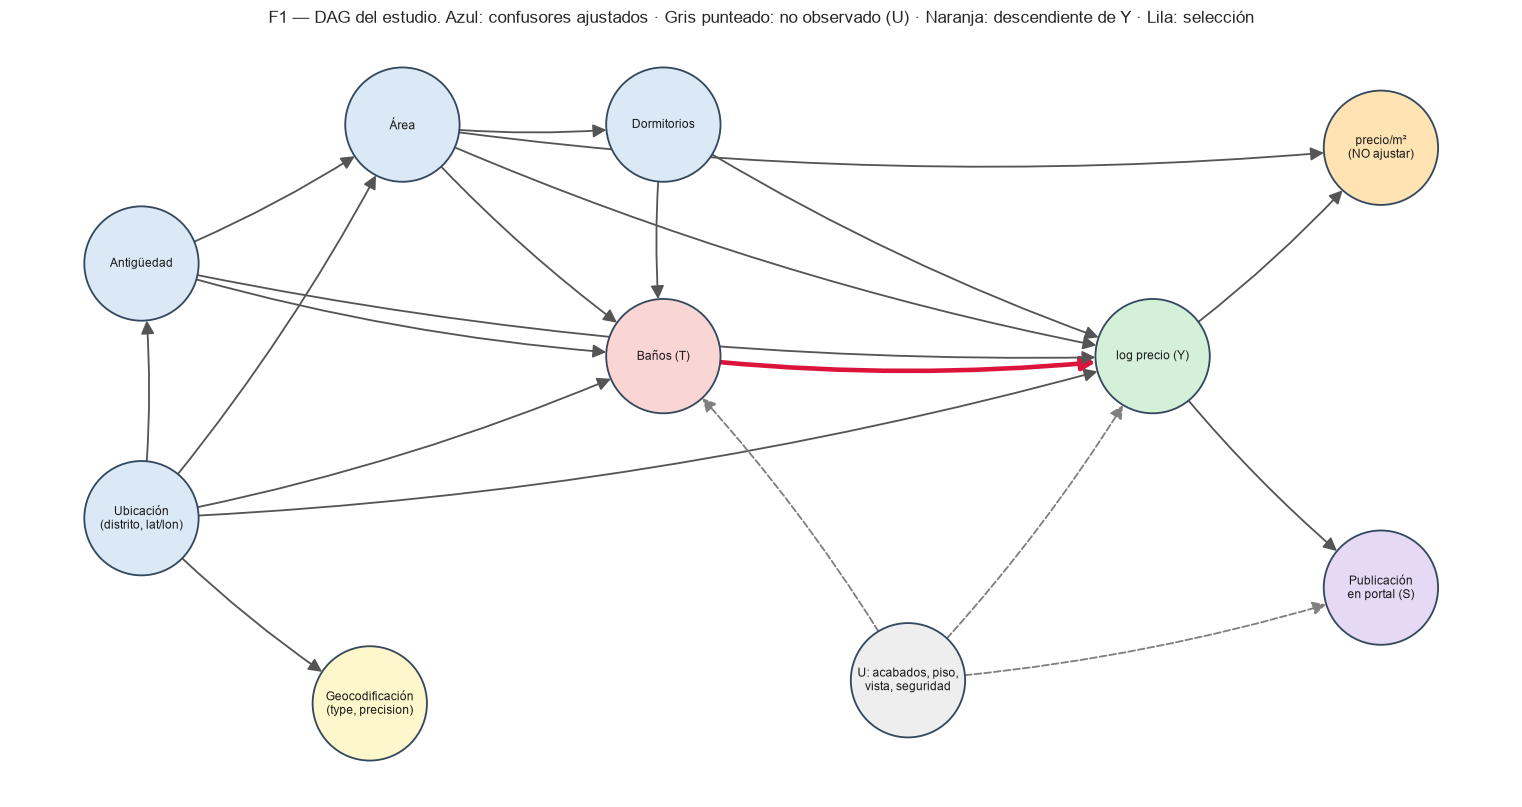

In [2]:
G1 = nx.DiGraph()
ar = [("Ubicación\n(distrito, lat/lon)", "Baños (T)"), ("Ubicación\n(distrito, lat/lon)", "log precio (Y)"),
      ("Ubicación\n(distrito, lat/lon)", "Antigüedad"), ("Ubicación\n(distrito, lat/lon)", "Área"),
      ("Antigüedad", "Área"), ("Antigüedad", "Baños (T)"), ("Antigüedad", "log precio (Y)"),
      ("Área", "Dormitorios"), ("Área", "Baños (T)"), ("Área", "log precio (Y)"),
      ("Dormitorios", "Baños (T)"), ("Dormitorios", "log precio (Y)"),
      ("Ubicación\n(distrito, lat/lon)", "Geocodificación\n(type, precision)"),
      ("log precio (Y)", "precio/m²\n(NO ajustar)"), ("Área", "precio/m²\n(NO ajustar)"),
      ("log precio (Y)", "Publicación\nen portal (S)")]
for u, v in ar: G1.add_edge(u, v)
G1.add_edge("Baños (T)", "log precio (Y)", color="crimson", w=3)
for v in ["Baños (T)", "log precio (Y)", "Publicación\nen portal (S)"]:
    G1.add_edge("U: acabados, piso,\nvista, seguridad", v, color="gray", style="dashed")
pos = {"Ubicación\n(distrito, lat/lon)": (0, 0), "Antigüedad": (0, 2.2), "Área": (1.6, 3.4), "Dormitorios": (3.2, 3.4),
       "Baños (T)": (3.2, 1.4), "log precio (Y)": (6.2, 1.4), "Geocodificación\n(type, precision)": (1.4, -1.6),
       "precio/m²\n(NO ajustar)": (7.6, 3.2), "Publicación\nen portal (S)": (7.6, -0.6), "U: acabados, piso,\nvista, seguridad": (4.7, -1.4)}
col = {"Baños (T)": "#f9d5d3", "log precio (Y)": "#d5f0d8", "U: acabados, piso,\nvista, seguridad": "#eeeeee",
       "precio/m²\n(NO ajustar)": "#ffe3b3", "Publicación\nen portal (S)": "#e6d9f5", "Geocodificación\n(type, precision)": "#fff7cc"}
fig, ax = plt.subplots(figsize=(14, 7.5))
nx.draw_networkx_nodes(G1, pos, node_size=5600, node_color=[col.get(n, "#dbe9f6") for n in G1.nodes],
                       edgecolors="#34495e", linewidths=1.2, ax=ax)
nx.draw_networkx_labels(G1, pos, font_size=8, ax=ax)
ax.set_xlim(-0.8, 8.4); ax.set_ylim(-2.4, 4.2)
for u, v, a in G1.edges(data=True):
    nx.draw_networkx_edges(G1, pos, edgelist=[(u, v)], ax=ax, arrows=True, arrowsize=18, node_size=5600,
                           width=a.get("w", 1.2), edge_color=a.get("color", "#555"), style=a.get("style", "solid"),
                           connectionstyle="arc3,rad=0.06")
ax.set_title("F1 — DAG del estudio. Azul: confusores ajustados · Gris punteado: no observado (U) · Naranja: descendiente de Y · Lila: selección", fontsize=11)
ax.axis("off"); plt.tight_layout(); plt.savefig(FIG / "F1_dag.png", bbox_inches="tight"); plt.show()

## 2. Estimación primaria (R3)

Se comparan (i) la asociación sin ajustar, (ii) el modelo hedónico OLS con el mismo conjunto de ajuste y (iii) Double ML.
Los diagnósticos de los modelos auxiliares (*nuisance*) se calculan **fuera de fold**.

In [3]:
b0, s0 = ols_efecto(Y, T, None, CL["edificio"])
b1, s1 = ols_efecto(Y, T, X.values, CL["edificio"])
dml = dml_plr(Y, T, X.values, G, CL, learner="HGB", n_rep=10)
th, se = dml["theta"], dml["se"]["edificio"]

r3 = pd.DataFrame({
  "estimador": ["Asociación sin ajustar (OLS)", "Hedónico OLS (S1 lineal)", "Double ML PLR (HGB, S1)"],
  "theta": [b0, b1, th], "EE (cluster edificio)": [s0, s1, se]})
r3["IC95 inf"] = r3["theta"] - 1.96 * r3["EE (cluster edificio)"]
r3["IC95 sup"] = r3["theta"] + 1.96 * r3["EE (cluster edificio)"]
r3["% por baño"] = pct(r3["theta"]); r3["% IC inf"] = pct(r3["IC95 inf"]); r3["% IC sup"] = pct(r3["IC95 sup"])
r3["S/ al mes (ref.)"] = REF * (np.exp(r3["theta"]) - 1)
r3["N"] = len(d)
guardar_tabla(r3, "R3_principal", origen=ORIGEN)
display(r3.round(4))
print("EE alternativos del DML -> iid: %.4f | edificio: %.4f | celda 1 km: %.4f" % (dml["se"]["iid"], dml["se"]["edificio"], dml["se"]["celda_1km"]))
print("Dispersión entre las 10 repeticiones del cross-fitting: min %.4f  max %.4f" % (dml["thetas"].min(), dml["thetas"].max()))

,estimador,theta,EE (cluster edificio),IC95 inf,IC95 sup,% por baño,% IC inf,% IC sup,S/ al mes (ref.),N
0,Asociación sin ajustar (OLS),0.3764,0.0127,0.3514,0.4013,45.6971,42.1029,49.3822,1199.5485,2220
1,Hedónico OLS (S1 lineal),0.0712,0.0111,0.0495,0.0929,7.3778,5.0704,9.7358,193.6670,2220
2,"Double ML PLR (HGB, S1)",0.0375,0.0103,0.0172,0.0578,3.8219,1.7379,5.9486,100.3250,2220


EE alternativos del DML -> iid: 0.0103 | edificio: 0.0103 | celda 1 km: 0.0119
Dispersión entre las 10 repeticiones del cross-fitting: min 0.0266  max 0.0406


In [4]:
# Comparación de learners para los modelos auxiliares (sin elegir por el coeficiente)
filas, res_l = [], {}
for lr in ["HGB", "GBR", "RF", "Lasso"]:
    r = dml if lr == "HGB" else dml_plr(Y, T, X.values, G, CL, learner=lr, n_rep=3)
    res_l[lr] = r
    filas.append({"learner": lr, "R2 fuera de fold E[Y|X]": r["r2_y"], "MAE E[Y|X]": r["mae_y"],
                  "R2 fuera de fold E[T|X]": r["r2_t"], "MAE E[T|X]": r["mae_t"],
                  "theta": r["theta"], "EE cluster": r["se"]["edificio"], "% por baño": pct(r["theta"])})
r3l = pd.DataFrame(filas)
guardar_tabla(r3l, "R3_learners", origen=ORIGEN)
r3l.round(4)

,learner,R2 fuera de fold E[Y|X],MAE E[Y|X],R2 fuera de fold E[T|X],MAE E[T|X],theta,EE cluster,% por baño
0,HGB,0.8137,0.1521,0.6274,0.3296,0.0375,0.0103,3.8219
1,GBR,0.8085,0.1537,0.6277,0.3328,0.0388,0.0102,3.9577
2,RF,0.8021,0.1558,0.6194,0.3201,0.0434,0.0108,4.4363
3,Lasso,0.7540,0.1785,0.6089,0.3570,0.0728,0.0113,7.5527


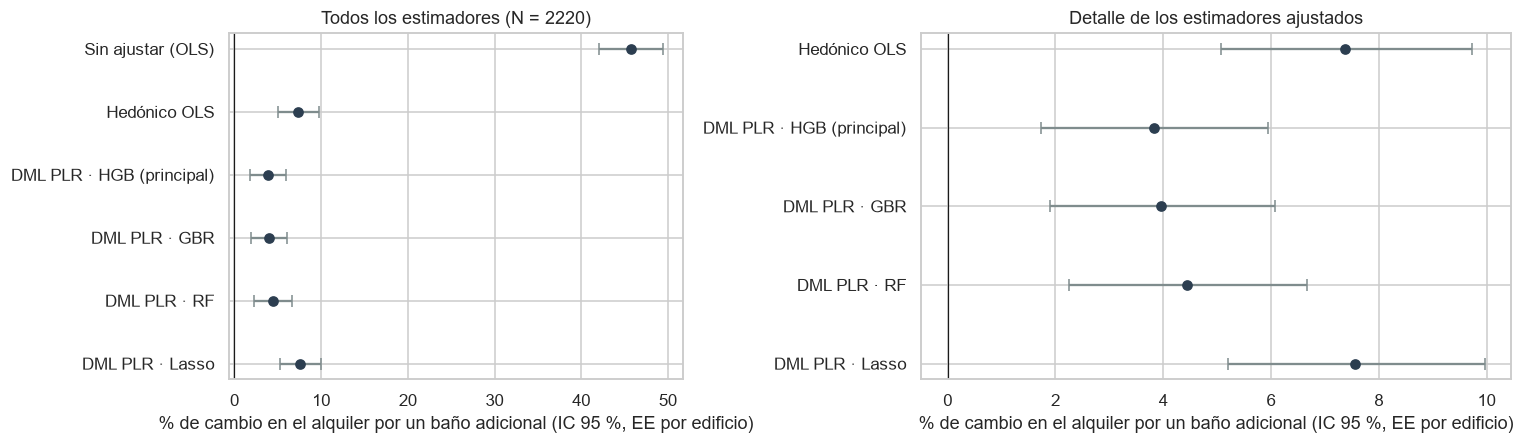

In [5]:
# F4: estimadores con IC 95 % y N
fp = pd.DataFrame([
  ("Sin ajustar (OLS)", b0, s0), ("Hedónico OLS", b1, s1)] +
  [(f"DML PLR · {k}" + (" (principal)" if k == "HGB" else ""), v["theta"], v["se"]["edificio"]) for k, v in res_l.items()],
  columns=["est", "theta", "se"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
for a, sub, lim in [(ax[0], fp, None), (ax[1], fp.iloc[1:], None)]:
    a.errorbar(pct(sub["theta"]), range(len(sub)), xerr=[pct(sub["theta"]) - pct(sub["theta"] - 1.96 * sub["se"]),
               pct(sub["theta"] + 1.96 * sub["se"]) - pct(sub["theta"])], fmt="o", capsize=4,
               color="#2c3e50", ecolor="#7f8c8d")
    a.set_yticks(range(len(sub))); a.set_yticklabels(sub["est"]); a.invert_yaxis(); a.axvline(0, color="k", lw=.8)
    a.set_xlabel("% de cambio en el alquiler por un baño adicional (IC 95 %, EE por edificio)")
ax[0].set_title(f"Todos los estimadores (N = {len(d)})"); ax[1].set_title("Detalle de los estimadores ajustados")
plt.tight_layout(); plt.savefig(FIG / "F4_estimadores.png", bbox_inches="tight"); plt.show()

## 3. Grilla de especificaciones (R4)

Se repite el DML cambiando **una sola decisión** a la vez. Las especificaciones S2–S4 omiten confusores; S6 agrega controles inadmisibles
(solo para demostrar el sesgo); S7 cambia el tratamiento del artefacto de geocodificación. Además se varían la depuración de datos
y la forma de partir los folds. S5 (proxy textual validado) corresponde al OE5, diferido en este entregable.

In [6]:
def correr(nombre, grupo, dd=None, num=NUM, cat=CAT, extra=(), folds_col="edificio_id", cl_col="edificio_id", n_rep=3):
    dd = d if dd is None else dd
    Xs = matriz(dd, num, cat, extra)
    r = dml_plr(dd["Y"].values, dd["T"].values, Xs.values, dd[folds_col].values,
                {"cl": dd[cl_col].values}, learner="HGB", n_rep=n_rep)
    t, s = r["theta"], r["se"]["cl"]
    return {"código": nombre.split(" ")[0], "especificación": nombre[len(nombre.split(" ")[0]) + 1:], "tipo": grupo,
            "N": len(dd), "theta": t, "EE": s, "IC95 inf": t - 1.96 * s, "IC95 sup": t + 1.96 * s, "% por baño": pct(t)}

sin = lambda *v: [c for c in NUM if c not in v]
d_nodup = muestra(base, dedup=False); d_min = muestra(base, filtro="minimo"); d_todas = muestra(base, solo_rooftop=False)
d_id = d.assign(fila=np.arange(len(d)))
grid = [
  correr("S1 Principal (conjunto del DAG)", "válida"),
  correr("S2 Sin área", "omite confusor", num=sin("area_log")),
  correr("S3 Sin ubicación (distrito, lat, lon)", "omite confusor", num=sin("latitud", "longitud"), cat=["tipo_ubic"]),
  correr("S4 Sin antigüedad", "omite confusor", num=sin("antig", "antig_na")),
  correr("S4b Sin dormitorios (efecto 'paquete')", "variante del DAG", num=sin("dormitorios")),
  correr("S6a + precio/m² (descendiente de Y)", "control inadmisible", extra=["precioxm2"]),
  correr("S6b + baños/dormitorio (función de T)", "control inadmisible", extra=["banos_dorm"]),
  correr("S7a Sin tipo de geocodificación", "artefacto de medición", cat=["distrito"]),
  correr("S8 + cochera extraída con IA (incluida / costo extra / ambigua)", "confusor medido con IA", extra=["coch_incluida", "coch_extra", "coch_ambigua"]),
  correr("D1 Sin deduplicar", "depuración", dd=d_nodup),
  correr("D2 Filtro mínimo (sin reglas de precio/m²)", "depuración", dd=d_min),
  correr("D3 Todas las precisiones de geocodificación (no solo ROOFTOP)", "depuración", dd=d_todas),
  correr("P1 Folds y EE por bloque espacial de 1 km", "partición", folds_col="celda_1km", cl_col="celda_1km"),
  correr("P2 Folds aleatorios (sin agrupar), EE iid", "partición", dd=d_id, folds_col="fila", cl_col="fila"),
]
r4 = pd.DataFrame(grid)
r4 = pd.concat([r4.iloc[:5], pd.DataFrame([{"código": "S5", "especificación": "S1 + proxy textual validado",
                "tipo": "no ejecutada (OE5 diferido)", "N": np.nan, "theta": np.nan, "EE": np.nan,
                "IC95 inf": np.nan, "IC95 sup": np.nan, "% por baño": np.nan}]), r4.iloc[5:]], ignore_index=True)
guardar_tabla(r4, "R4_especificaciones", origen=ORIGEN)
r4.round(4)

,código,especificación,tipo,N,theta,EE,IC95 inf,IC95 sup,% por baño
0,S1,Principal (conjunto del DAG),válida,2220.0,0.0378,0.0102,0.0179,0.0578,3.8541
1,S2,Sin área,omite confusor,2220.0,0.1781,0.0157,0.1474,0.2089,19.4991
2,S3,"Sin ubicación (distrito, lat, lon)",omite confusor,2220.0,0.0802,0.0135,0.0537,0.1067,8.3534
3,S4,Sin antigüedad,omite confusor,2220.0,0.0593,0.0102,0.0394,0.0792,6.1052
4,S4b,Sin dormitorios (efecto 'paquete'),variante del DAG,2220.0,0.0539,0.0098,0.0347,0.0730,5.5370
5,S5,S1 + proxy textual validado,no ejecutada (OE5 diferido),NaN,NaN,NaN,NaN,NaN,NaN
6,S6a,+ precio/m² (descendiente de Y),control inadmisible,2220.0,-0.0032,0.0024,-0.0079,0.0016,-0.3145
7,S6b,+ baños/dormitorio (función de T),control inadmisible,2220.0,-0.0124,0.1621,-0.3301,0.3053,-1.2332
8,S7a,Sin tipo de geocodificación,artefacto de medición,2220.0,0.0364,0.0106,0.0156,0.0571,3.7034
9,S8,+ cochera extraída con IA (incluida / costo ex...,confusor medido con IA,2220.0,0.0340,0.0103,0.0139,0.0541,3.4571


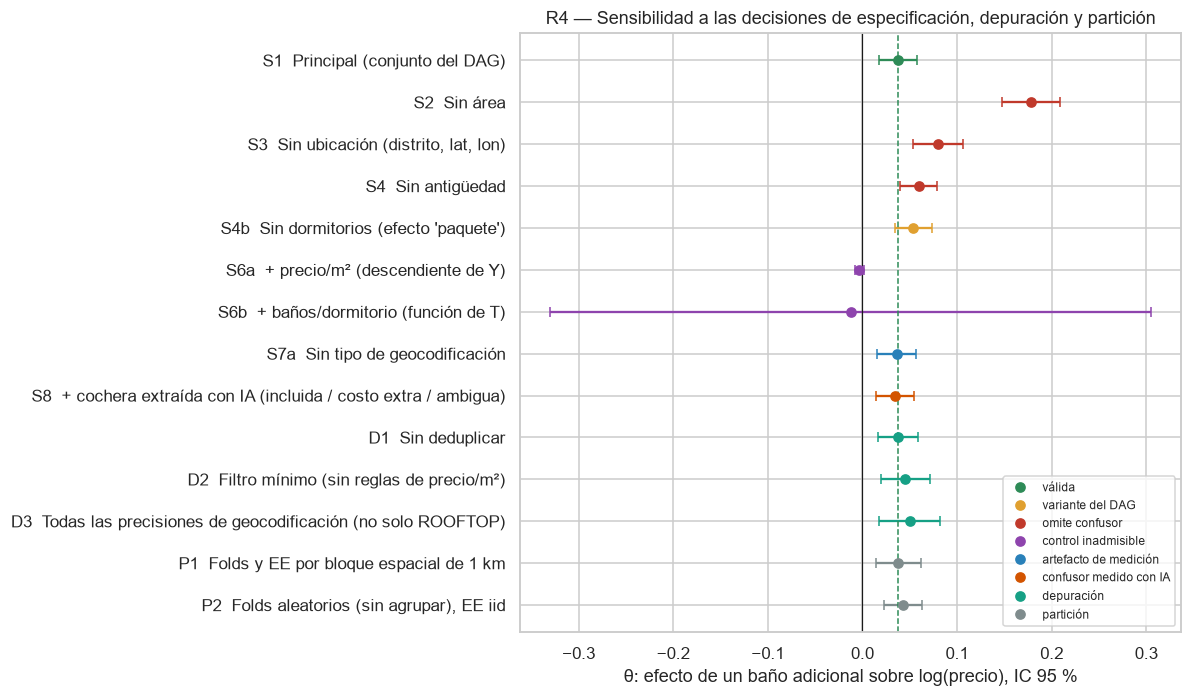

In [7]:
p = r4.dropna(subset=["theta"]).reset_index(drop=True)
paleta = {"válida": "#2e8b57", "variante del DAG": "#e0a030", "omite confusor": "#c0392b", "control inadmisible": "#8e44ad",
          "artefacto de medición": "#2980b9", "confusor medido con IA": "#d35400", "depuración": "#16a085", "partición": "#7f8c8d"}
fig, ax = plt.subplots(figsize=(11, 6.5))
for i, rr in p.iterrows():
    ax.errorbar(rr["theta"], i, xerr=[[rr["theta"] - rr["IC95 inf"]], [rr["IC95 sup"] - rr["theta"]]], fmt="o",
                color=paleta[rr["tipo"]], capsize=3)
ax.set_yticks(range(len(p))); ax.set_yticklabels(p["código"] + "  " + p["especificación"]); ax.invert_yaxis()
ax.axvline(0, color="k", lw=.8); ax.axvline(p.loc[0, "theta"], color="#2e8b57", ls="--", lw=1)
for t, c in paleta.items(): ax.plot([], [], "o", color=c, label=t)
ax.legend(fontsize=8, loc="lower right"); ax.set_xlabel("θ: efecto de un baño adicional sobre log(precio), IC 95 %")
ax.set_title("R4 — Sensibilidad a las decisiones de especificación, depuración y partición")
plt.tight_layout(); plt.savefig(FIG / "F4b_especificaciones.png", bbox_inches="tight"); plt.show()

## 4. Robustez a confusores no observados (R5)

La variable omitida U (acabados, piso, vista, seguridad) no se puede medir con estos datos. Lo que sí puede calcularse es **cuán fuerte**
tendría que ser para cambiar la conclusión. Con R²<sub>Y</sub> = parte de la varianza residual de Y explicada por U y R²<sub>T</sub> = parte
de la varianza residual de T explicada por U, el sesgo máximo del DML-PLR es

$$|\text{sesgo}| \le \sqrt{\frac{R^2_Y\,R^2_T}{1-R^2_T}}\;\frac{\sigma_\varepsilon}{\sigma_{\tilde T}}$$

* **Valor de robustez (RV)**: fuerza común (R²<sub>Y</sub> = R²<sub>T</sub>) que lleva θ a 0; **RV<sub>α</sub>** la que lleva el límite inferior del IC a 0.
* **Benchmarks**: se re-estima el modelo omitiendo un bloque de confusores observados y se mide cuánto explicaba de T y de Y.
  Así se responde: *¿un U tan fuerte como el área (o la ubicación) anularía el efecto?*

In [8]:
largo = dml_plr(Y, T, X.values, G, CL, learner="HGB", n_rep=1)
ve, vt = np.var(largo["eps"]), np.var(largo["rt"])
bloques = {"área": dict(num=sin("area_log")), "ubicación": dict(num=sin("latitud", "longitud"), cat=["tipo_ubic"]),
           "dormitorios": dict(num=sin("dormitorios")), "antigüedad": dict(num=sin("antig", "antig_na"))}
bench = {}
for k, kw in bloques.items():
    Xs = matriz(d, kw.get("num", NUM), kw.get("cat", CAT))
    corto = dml_plr(Y, T, Xs.values, G, CL, learner="HGB", n_rep=1)
    bench[k] = benchmark(largo, corto)

rv = valor_robustez(th, ve, vt); rva = valor_robustez(th, ve, vt, se=se, z=1.96)
filas = [{"referencia": "Estimación DML principal", "R2 con T": np.nan, "R2 con Y": np.nan, "theta ajustado": th,
          "IC95 inf ajustado": th - 1.96 * se, "% ajustado": pct(th)}]
for k, (r2d, r2y) in bench.items():
    for mult in (1, 2):
        b = sesgo_max(mult * r2y, mult * r2d, ve, vt)
        filas.append({"referencia": f"U {mult}× tan fuerte como {k}", "R2 con T": mult * r2d, "R2 con Y": mult * r2y,
                      "theta ajustado": th - b, "IC95 inf ajustado": th - b - 1.96 * se, "% ajustado": pct(th - b)})
r5 = pd.DataFrame(filas)
guardar_tabla(r5, "R5_sensibilidad", origen=ORIGEN)
d_ev = abs(th) / np.std(Y); RR = np.exp(0.91 * d_ev); ev = RR + np.sqrt(RR * (RR - 1))
r5b = pd.DataFrame({"indicador": ["RV (θ → 0)", "RV_α (límite inferior IC → 0)", "E-value (VanderWeele-Ding, escala d = θ/DE(Y))"],
                    "valor": [rv, rva, ev]})
guardar_tabla(r5b, "R5_robustez", origen=ORIGEN)
display(r5b.round(4)); r5.round(4)

,indicador,valor
0,RV (θ → 0),0.0791
1,RV_α (límite inferior IC → 0),0.0371
2,"E-value (VanderWeele-Ding, escala d = θ/DE(Y))",1.3522


,referencia,R2 con T,R2 con Y,theta ajustado,IC95 inf ajustado,% ajustado
0,Estimación DML principal,NaN,NaN,0.0375,0.0172,3.8219
1,U 1× tan fuerte como área,0.1522,0.4451,-0.0912,-0.1115,-8.7147
2,U 2× tan fuerte como área,0.3045,0.8901,-0.2466,-0.2669,-21.8580
3,U 1× tan fuerte como ubicación,0.0232,0.3978,-0.0067,-0.0270,-0.6713
4,U 2× tan fuerte como ubicación,0.0464,0.7955,-0.0520,-0.0723,-5.0717
5,U 1× tan fuerte como dormitorios,0.2038,0.0168,0.0077,-0.0126,0.7732
6,U 2× tan fuerte como dormitorios,0.4076,0.0335,-0.0316,-0.0519,-3.1104
7,U 1× tan fuerte como antigüedad,0.0443,0.0950,0.0073,-0.0130,0.7331
8,U 2× tan fuerte como antigüedad,0.0886,0.1900,-0.0243,-0.0446,-2.4054


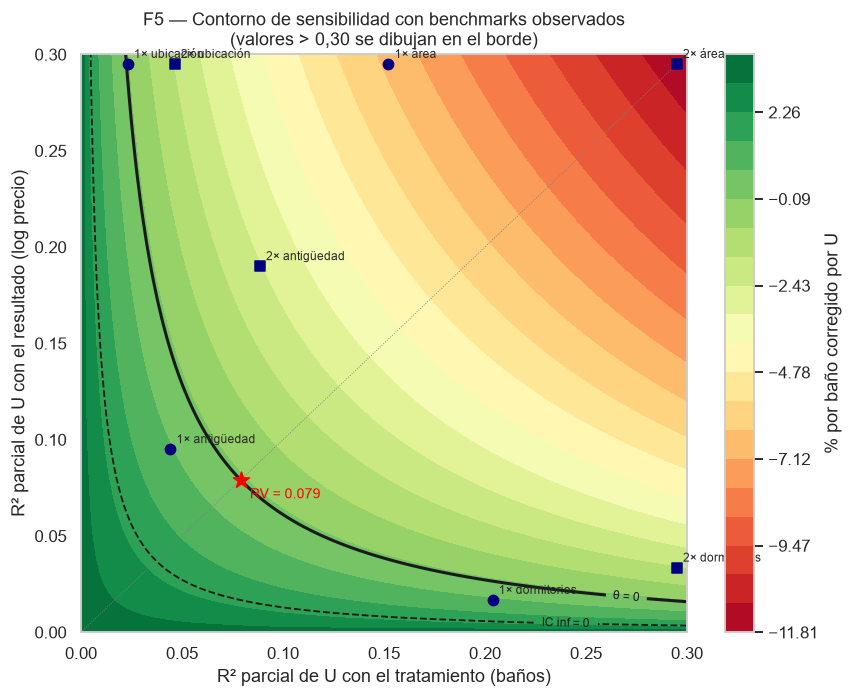

In [9]:
g = np.linspace(0, 0.30, 121); R2T, R2Y = np.meshgrid(g, g)
aj = th - sesgo_max(R2Y, R2T, ve, vt)
fig, ax = plt.subplots(figsize=(8, 6.5))
cs = ax.contourf(R2T, R2Y, pct(aj), levels=np.linspace(pct(aj).min(), pct(th), 21), cmap="RdYlGn")
plt.colorbar(cs, label="% por baño corregido por U")
c0 = ax.contour(R2T, R2Y, aj, levels=[0], colors="k", linewidths=2)
c1 = ax.contour(R2T, R2Y, aj - 1.96 * se, levels=[0], colors="k", linewidths=1.2, linestyles="--")
ax.clabel(c0, fmt={0: "θ = 0"}, fontsize=8); ax.clabel(c1, fmt={0: "IC inf = 0"}, fontsize=8)
for k, (r2d, r2y) in bench.items():
    for mult, mk in ((1, "o"), (2, "s")):
        x_, y_ = min(mult * r2d, .295), min(mult * r2y, .295)
        ax.scatter(x_, y_, c="navy", marker=mk, s=45, zorder=3)
        ax.annotate(f"{mult}× {k}", (x_, y_), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.plot([0, .3], [0, .3], color="gray", lw=.6, ls=":"); ax.scatter(rv, rv, c="red", marker="*", s=120, zorder=4)
ax.annotate(f"RV = {rv:.3f}", (rv, rv), xytext=(6, -12), textcoords="offset points", color="red", fontsize=9)
ax.set_xlabel("R² parcial de U con el tratamiento (baños)"); ax.set_ylabel("R² parcial de U con el resultado (log precio)")
ax.set_title("F5 — Contorno de sensibilidad con benchmarks observados\n(valores > 0,30 se dibujan en el borde)")
plt.tight_layout(); plt.savefig(FIG / "F5_sensibilidad.png", bbox_inches="tight"); plt.show()

## 5. Heterogeneidad preespecificada (R7)

GATE por **clase de distrito** (clase1 = Miraflores, San Isidro, Barranco, Lince; clase2 = Magdalena, Surquillo, Jesús María, San Borja,
Surco; clase3 = Cercado, San Miguel, Chorrillos, La Molina) y por **quintil de área**. Cada θ<sub>g</sub> usa los residuos fuera de fold
del modelo principal; la covarianza entre grupos es agrupada por edificio y se reportan IC simultáneos (Bonferroni) y una prueba de Wald
de igualdad. El CATE individual (bosque causal) **no** se reporta como resultado: en el entregable previo su IC incluía el 0.

In [10]:
d["quintil_area"] = pd.qcut(d["area"], 5, labels=[f"Q{i}" for i in range(1, 6)])
rng_q = d.groupby("quintil_area", observed=True)["area"].agg(["min", "max"])
tabs = []
for seg, nom in [("distrito_clase", "clase de distrito"), ("quintil_area", "quintil de área")]:
    tb, w, pw = gate(dml["rt"], dml["ry"], d[seg].astype(str).values, CL["edificio"])
    tb.insert(0, "segmentación", nom); tb["% por baño"] = pct(tb["theta"])
    tb["Wald (igualdad)"] = w; tb["p-valor Wald"] = pw
    tabs.append(tb)
r7 = pd.concat(tabs, ignore_index=True)
r7["grupo"] = [g if not g.startswith("Q") else f"{g} ({rng_q.loc[g,'min']:.0f}-{rng_q.loc[g,'max']:.0f} m2)" for g in r7["grupo"]]
guardar_tabla(r7, "R7_gate", origen=ORIGEN)
r7.round(4)

,segmentación,grupo,n,theta,ee,ic_inf,ic_sup,ic_sim_inf,ic_sim_sup,% por baño,Wald (igualdad),p-valor Wald
0,clase de distrito,clase1,983,0.0204,0.0171,-0.0131,0.0538,-0.0205,0.0612,2.0592,2.3370,0.3108
1,clase de distrito,clase2,679,0.0563,0.0162,0.0246,0.0880,0.0175,0.0950,5.7874,2.3370,0.3108
2,clase de distrito,clase3,558,0.0378,0.0191,0.0003,0.0753,-0.0080,0.0836,3.8536,2.3370,0.3108
3,quintil de área,Q1 (20-52 m2),446,0.0481,0.0352,-0.0208,0.1170,-0.0425,0.1386,4.9241,2.4734,0.6494
4,quintil de área,Q2 (53-70 m2),489,0.0501,0.0250,0.0011,0.0990,-0.0142,0.1144,5.1356,2.4734,0.6494
5,quintil de área,Q3 (70-88 m2),401,0.0583,0.0214,0.0164,0.1001,0.0032,0.1133,5.9982,2.4734,0.6494
6,quintil de área,Q4 (89-120 m2),470,0.0189,0.0173,-0.0149,0.0528,-0.0255,0.0634,1.9120,2.4734,0.6494
7,quintil de área,Q5 (120-570 m2),414,0.0346,0.0196,-0.0038,0.0730,-0.0158,0.0851,3.5231,2.4734,0.6494


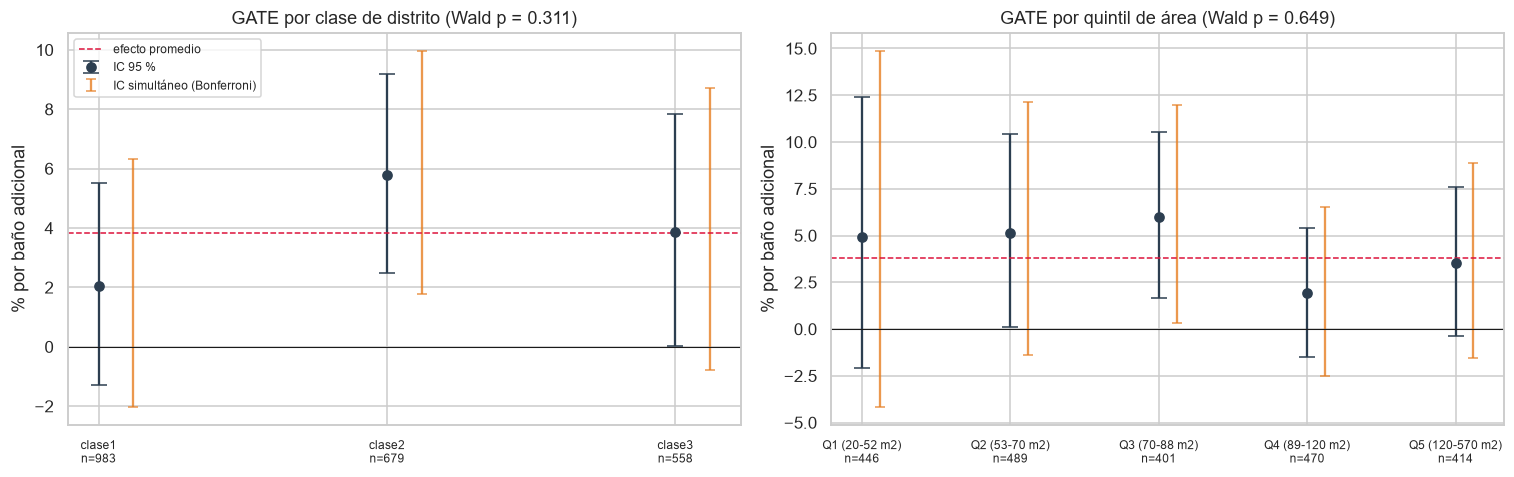

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for a, nom in zip(ax, ["clase de distrito", "quintil de área"]):
    s = r7[r7["segmentación"] == nom].reset_index(drop=True)
    a.errorbar(range(len(s)), pct(s["theta"]), yerr=[pct(s["theta"]) - pct(s["ic_inf"]), pct(s["ic_sup"]) - pct(s["theta"])],
               fmt="o", capsize=5, color="#2c3e50", label="IC 95 %")
    a.errorbar(np.arange(len(s)) + .12, pct(s["theta"]), yerr=[pct(s["theta"]) - pct(s["ic_sim_inf"]), pct(s["ic_sim_sup"]) - pct(s["theta"])],
               fmt="none", capsize=3, color="#e67e22", alpha=.8, label="IC simultáneo (Bonferroni)")
    a.axhline(pct(th), color="crimson", ls="--", lw=1, label="efecto promedio"); a.axhline(0, color="k", lw=.7)
    a.set_xticks(range(len(s))); a.set_xticklabels([f"{g}\nn={n}" for g, n in zip(s["grupo"], s["n"])], fontsize=8)
    a.set_title(f"GATE por {nom} (Wald p = {s['p-valor Wald'].iloc[0]:.3f})"); a.set_ylabel("% por baño adicional")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "F7_heterogeneidad.png", bbox_inches="tight"); plt.show()

## 6. Dependencia espacial

¿Quedan patrones espaciales en los residuos? Se calcula el **I de Moran** (10 vecinos más cercanos, p-valor por 999 permutaciones) para:
el residuo del precio dado X, el residuo del tratamiento dado X y el residuo final del modelo. Si hay autocorrelación, la inferencia iid
subestima la incertidumbre; por eso la inferencia principal agrupa por edificio y se reporta la agrupación por bloques de 1 km.

In [12]:
vec = vecinos_knn(d["latitud"], d["longitud"], k=10)
filas = []
for nom, z in [("Residuo de log precio | X", dml["ry"]), ("Residuo de baños | X", dml["rt"]), ("Residuo final ε", dml["eps"])]:
    I, p_, e0 = moran_i(z, vec)
    filas.append({"serie": nom, "I de Moran": I, "E[I] bajo permutación": e0, "p-valor": p_})
esp = pd.DataFrame(filas)
esp2 = pd.DataFrame({"inferencia del DML principal": ["iid (ignora dependencia)", "cluster por edificio (principal)", "cluster por bloque de 1 km"],
                     "EE": [dml["se"]["iid"], dml["se"]["edificio"], dml["se"]["celda_1km"]]})
esp2["IC95 inf"] = th - 1.96 * esp2["EE"]; esp2["IC95 sup"] = th + 1.96 * esp2["EE"]; esp2["razón vs iid"] = esp2["EE"] / dml["se"]["iid"]
guardar_tabla(esp, "E7_moran", origen=ORIGEN); guardar_tabla(esp2, "E7_inferencia", origen=ORIGEN)
display(esp.round(4)); esp2.round(4)

,serie,I de Moran,E[I] bajo permutación,p-valor
0,Residuo de log precio | X,0.0113,-0.0001,0.120
1,Residuo de baños | X,-0.0116,-0.0008,0.902
2,Residuo final ε,0.0120,-0.0001,0.100


,inferencia del DML principal,EE,IC95 inf,IC95 sup,razón vs iid
0,iid (ignora dependencia),0.0103,0.0173,0.0577,1.0000
1,cluster por edificio (principal),0.0103,0.0172,0.0578,1.0029
2,cluster por bloque de 1 km,0.0119,0.0142,0.0608,1.1506


In [13]:
import json
resumen = {"N": len(d), "theta": th, "se": se, "pct": pct(th), "ic_pct": [pct(th - 1.96 * se), pct(th + 1.96 * se)],
           "soles_ref": REF * (np.exp(th) - 1), "ref": REF, "rv": rv, "rva": rva, "evalue": ev,
           "ols_naive": b0, "ols_hed": b1, "r2_y": dml["r2_y"], "r2_t": dml["r2_t"],
           "bench": {k: list(v) for k, v in bench.items()}, "var_eps": ve, "var_rt": vt}
(RES / "resumen_principal.json").write_text(json.dumps(resumen, indent=2, default=float), encoding="utf-8")
print(json.dumps(resumen, indent=1, default=float))

{
 "N": 2220,
 "theta": 0.03750679506169666,
 "se": 0.010345561100770338,
 "pct": 3.8219051820368,
 "ic_pct": [
  1.7378779187992244,
  5.948622245010382
 ],
 "soles_ref": 100.325011028466,
 "ref": 2625.0,
 "rv": 0.0790740172688774,
 "rva": 0.03714198964536599,
 "evalue": 1.3522290594959991,
 "ols_naive": 0.3763595371195494,
 "ols_hed": 0.07118318474940719,
 "r2_y": 0.8137303500490577,
 "r2_t": 0.6274151991018602,
 "bench": {
  "\u00e1rea": [
   0.15224178538163236,
   0.4450723855276751
  ],
  "ubicaci\u00f3n": [
   0.023199581057463045,
   0.3977701233845806
  ],
  "dormitorios": [
   0.20379017509477582,
   0.01675031626816159
  ],
  "antig\u00fcedad": [
   0.044284240317664814,
   0.09501241380913057
  ]
 },
 "var_eps": 0.045015840138935816,
 "var_rt": 0.21726427924129393
}


## 7. Conclusiones de este notebook (muestra ROOFTOP, N = 2 220)

* **H1 (se confirma).** La asociación sin ajustar (≈ 46 % por baño) cae a ≈ 7.4 % con el hedónico lineal y a **≈ 3.8 % con DML (IC 95 %: 1.7–6.0 %)**, unos S/ 100 al mes sobre un alquiler de S/ 2 625.
* **Cochera como control (S8).** Agregar la cochera extraída con IA reduce poco el efecto (3.5 %): la cochera no explicaba la mayor parte del efecto del baño.
* **H2 (se confirma).** Sin área: 19.5 %; sin ubicación: 8.4 %; con precio/m²: ≈ 0. Las alternativas defendibles quedan entre 3.5 y 5.5 %. Con todas las precisiones de geocodificación (no solo ROOFTOP) el efecto sube a 5.1 %: la ubicación imprecisa lo inflaba.
* **H3 (sin respaldo).** GATE por clase de distrito (p = 0.31) y por quintil de área (p = 0.65) sin diferencias significativas.
* **H4 (se confirma, fragilidad mayor que con toda la muestra).** RV ≈ 0.079; un confusor omitido tan fuerte como la antigüedad o como la ubicación ya llevaría el efecto a cerca de 0.
* **Dependencia espacial.** Con direcciones exactas, la autocorrelación residual deja de ser significativa (I de Moran ≈ 0.01, p = 0.10) y el R² fuera de fold del precio sube de 0.68 a 0.81.
